1. Подготовка данных

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Загрузка данных

In [2]:
df = pd.read_csv('titanic.csv')

Выбор признаков

In [3]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

Проверка пропущенных значений

In [4]:
print(df[features + [target]].isnull().sum())

Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


Обработка пропусков в Age (заполняем медианой)

In [5]:
df['Age'] = df['Age'].fillna(df['Age'].median())

Преобразование Sex в числовой формат

In [6]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

Проверка результата

In [7]:
print(df['Sex'].unique())
print(df['Sex'].dtype)

[0 1]
int64


Формирование таблицы для корреляционного анализа

In [8]:
corr_data = df[features + [target]]

print("Столбцы:", corr_data.columns.tolist())
print("Типы данных:\n", corr_data.dtypes)
print("Пропущенные значения:\n", corr_data.isnull().sum())

Столбцы: ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']
Типы данных:
 Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object
Пропущенные значения:
 Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


2. Расчёт корреляционной матрицы

Корреляционная матрица

In [9]:
corr_matrix = corr_data.corr()

Округление до двух знаков

In [10]:
corr_matrix_rounded = corr_matrix.round(2)
print(corr_matrix_rounded)

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


Корреляции с целевой переменной Survived (исключая саму себя)

In [11]:
survived_corr = corr_matrix_rounded['Survived'].drop('Survived')

Наиболее сильная положительная корреляция

In [12]:
max_pos = survived_corr.idxmax()
max_pos_value = survived_corr.max()

Наиболее сильная отрицательная корреляция

In [13]:
max_neg = survived_corr.idxmin()
max_neg_value = survived_corr.min()

print(f"Наиболее сильная положительная корреляция с Survived: {max_pos} ({max_pos_value})")
print(f"Наиболее сильная отрицательная корреляция с Survived: {max_neg} ({max_neg_value})")

Наиболее сильная положительная корреляция с Survived: Sex (0.54)
Наиболее сильная отрицательная корреляция с Survived: Pclass (-0.34)


3. Построение тепловой карты

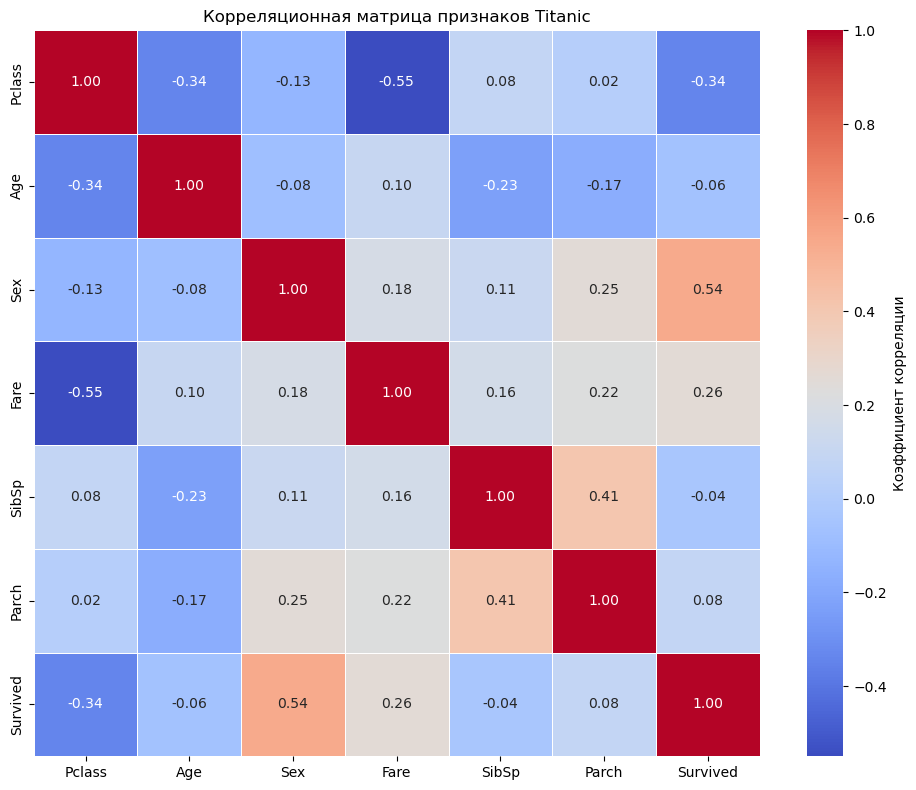

In [14]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix_rounded,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True,
    cbar_kws={'label': 'Коэффициент корреляции'}
)

plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()

4. Корреляция и машинное обучение

Признаки X и целевая переменная y

In [15]:
X = df[features]
y = df[target]

print("Признаки X:")
print(X.head())
print("\nЦелевая переменная y:")
print(y.head())

Признаки X:
   Pclass   Age  Sex     Fare  SibSp  Parch
0       3  22.0    0   7.2500      1      0
1       1  38.0    1  71.2833      1      0
2       3  26.0    1   7.9250      0      0
3       1  35.0    1  53.1000      1      0
4       3  35.0    0   8.0500      0      0

Целевая переменная y:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64
